# 01 · Inspect NYC CityGML

**Goal:** understand the files before building a parser or solar model. Run cells from top to bottom using this project's `.venv` Python interpreter. In VS Code, use **Select Kernel → Python Environments → .venv**. You can also launch Jupyter with `uv run jupyter lab` from the repository root and select the project environment. Change the file and sample size below to explore another delivery area.

Our roadmap is **Inspect → Parse → Transform → Analyze → Visualize**. This notebook covers Inspect only; it reads local data without changing it.

CityGML is XML that combines **meaning** (this is a roof) with **geometry** (these vertices describe its boundary). A point cloud is a collection of measured points, often from LiDAR. Here the building surfaces are already modeled, so we can inspect their boundaries directly:

`CityModel → cityObjectMember → Building → boundedBy → RoofSurface / WallSurface / GroundSurface → lod2MultiSurface → MultiSurface → Polygon → exterior / interior → LinearRing → posList`

A polygon has an exterior ring and may have interior rings (holes). A `posList` contains coordinate numbers; its dimension determines how to group those numbers into vertices. LoD means *Level of Detail*. An observed `lod2` tag tells us how geometry is encoded; it does not prove that every roof has detailed roof structures.

In [1]:
from pathlib import Path
import copy
from collections import Counter
import xml.etree.ElementTree as ET

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from pyproj import CRS, Transformer
from IPython.display import display, Markdown

# Support launching Jupyter from the repository root or notebooks directory.
ROOT = Path.cwd().resolve()
if not (ROOT / "pyproject.toml").exists() and (ROOT.parent / "pyproject.toml").exists():
    ROOT = ROOT.parent
DATA = ROOT / "data" / "DA_WISE_GML"
GML_FILE = DATA / "DA_WISE_GMLs" / "DA1_3D_Buildings_Merged.gml"
SAMPLE_SIZE = 100
assert GML_FILE.is_file(), f"CityGML file not found: {GML_FILE}"
assert isinstance(SAMPLE_SIZE, int) and SAMPLE_SIZE > 0
plt.rcParams["figure.figsize"] = (9, 6)
print(f"File: {GML_FILE.name} | maximum sampled buildings: {SAMPLE_SIZE}")

File: DA1_3D_Buildings_Merged.gml | maximum sampled buildings: 100


## 1. Inventory and delivery areas

The GML files partition the model into delivery areas, not individual buildings. The companion shapefile supplies their boundaries. File size is not a building count.

,file,MiB
0,DA1_3D_Buildings_Merged.gml,266.7
1,DA2_3D_Buildings_Merged.gml,272.6
2,DA3_3D_Buildings_Merged.gml,274.1
3,DA4_3D_Buildings_Merged.gml,208.0
4,DA5_3D_Buildings_Merged.gml,491.0
5,DA6_3D_Buildings_Merged.gml,728.9
6,DA7_3D_Buildings_Merged.gml,687.7
7,DA8_3D_Buildings_Merged.gml,667.4
8,DA9_3D_Buildings_Merged.gml,659.7
9,DA10_3D_Buildings_Merged.gml,545.9


20 files; 12.84 GiB total
Delivery areas: 20 | CRS: EPSG:2263


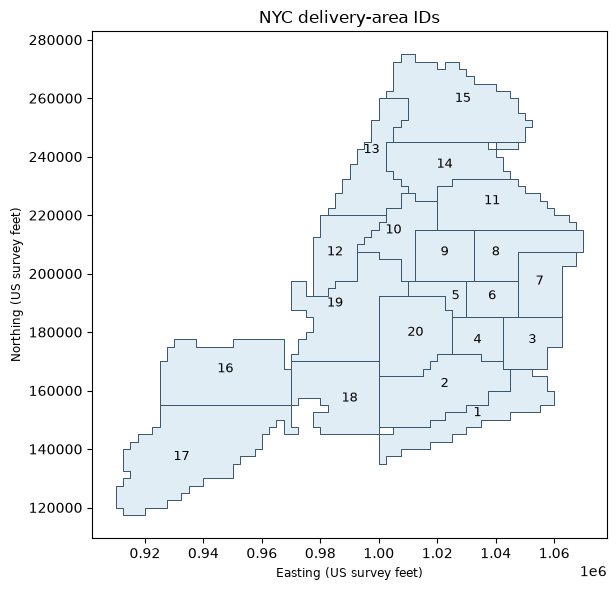

In [2]:
files = sorted(GML_FILE.parent.glob("*.gml"), key=lambda p: int(p.name.split("_")[0][2:]))
inventory = pd.DataFrame({"file": [p.name for p in files],
                          "MiB": [p.stat().st_size / 1024**2 for p in files]})
display(inventory.round(1))
print(f"{len(files)} files; {inventory.MiB.sum() / 1024:.2f} GiB total")

areas = gpd.read_file(DATA / "DeliveryArea.shp")
print(f"Delivery areas: {len(areas)} | CRS: {areas.crs}")
fig, ax = plt.subplots()
areas.plot(ax=ax, facecolor="#e1edf5", edgecolor="#36556d", linewidth=0.7)
for _, row in areas.iterrows():
    point = row.geometry.representative_point()
    ax.text(point.x, point.y, str(int(row["DELIVERY_A"])), ha="center", fontsize=9)
ax.set(title="NYC delivery-area IDs", xlabel="Easting (US survey feet)", ylabel="Northing (US survey feet)")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

## 2. Read a bounded sample

`iterparse` reads XML incrementally. We process complete top-level city-object members and remove them from the root afterward, so previously visited buildings do not accumulate in the XML tree. We keep only sample summaries, coordinate arrays, and the first building for display. The file closes when the sample limit is reached.

This is **sample inspection**, not a general CityGML reader. Inline `posList` rings are inspected; other coordinate encodings and references are reported rather than resolved. Namespace declarations also do not imply that those kinds of objects occur in the file.

In [3]:
NS = {"core": "http://www.opengis.net/citygml/2.0",
      "bldg": "http://www.opengis.net/citygml/building/2.0",
      "gml": "http://www.opengis.net/gml",
      "gen": "http://www.opengis.net/citygml/generics/2.0"}
GML_ID = "{" + NS["gml"] + "}id"
XLINK = "{http://www.w3.org/1999/xlink}href"
SURFACE_TYPES = {"RoofSurface", "WallSurface", "GroundSurface", "ClosureSurface",
                 "OuterCeilingSurface", "OuterFloorSurface"}
GEOMETRY_TYPES = {"MultiSurface", "CompositeSurface", "Surface", "Polygon", "LinearRing",
                  "Solid", "CompositeSolid", "MultiSolid", "Point", "LineString",
                  "TriangulatedSurface", "Triangle", "Tin", "OrientableSurface"}

def local(tag):
    return tag.rsplit("}", 1)[-1]

namespaces, envelope = {}, {}
element_counts, geometry_counts, surface_counts = Counter(), Counter(), Counter()
metadata_counts, crs_counts, dimension_counts = Counter(), Counter(), Counter()
issues, buildings, rings, references = [], [], [], []
first_building = None
other_objects = Counter()

with GML_FILE.open("rb") as source:
    root = None
    for event, element in ET.iterparse(source, events=("start-ns", "start", "end")):
        if event == "start-ns":
            prefix, uri = element
            namespaces[prefix or "(default)"] = uri
            continue
        if event == "start":
            if root is None:
                root = element
                assert element.tag == "{" + NS["core"] + "}CityModel", "Expected CityGML 2.0 CityModel"
            continue
        if element.tag == "{" + NS["gml"] + "}Envelope" and not envelope:
            envelope = {**element.attrib,
                        "lowerCorner": element.findtext("gml:lowerCorner", namespaces=NS),
                        "upperCorner": element.findtext("gml:upperCorner", namespaces=NS)}
        if element.tag != "{" + NS["core"] + "}cityObjectMember":
            continue
        for child in element:
            if child.tag != "{" + NS["bldg"] + "}Building":
                other_objects[local(child.tag)] += 1
                continue
            building = child
            bid = building.get(GML_ID, "(missing gml:id)")
            if first_building is None:
                first_building = copy.deepcopy(building)
            attrs = {}
            for attr in building:
                if attr.tag.startswith("{" + NS["gen"] + "}") and local(attr.tag).endswith("Attribute"):
                    key = attr.get("name", "(unnamed)")
                    attrs[key] = attr.findtext("gen:value", namespaces=NS)
                    metadata_counts[key] += 1
            buildings.append({"gml_id": bid, "name": building.findtext("gml:name", namespaces=NS), **attrs})
            for node in building.iter():
                tag = local(node.tag)
                element_counts[tag] += 1
                if tag in GEOMETRY_TYPES:
                    geometry_counts[tag] += 1
                if node.get("srsName"):
                    crs_counts[node.get("srsName")] += 1
                if node.get("srsDimension"):
                    dimension_counts[node.get("srsDimension")] += 1
                if XLINK in node.attrib:
                    references.append({"building": bid, "element": tag, "href": node.get(XLINK)})
                if tag in {"pos", "coordinates", "coord"}:
                    issues.append({"building": bid, "issue": f"Coordinate encoding {tag}: not decoded"})
                if tag == "BuildingPart":
                    issues.append({"building": bid, "issue": "BuildingPart present; inspect hierarchy before Stage 2"})
            parent_map = {c: p for p in building.iter() for c in p}
            def inherited(node, key):
                while node is not None:
                    if key in node.attrib:
                        return node.get(key)
                    node = parent_map.get(node)
                return envelope.get(key)
            for surface in building.iter():
                stype = local(surface.tag)
                if stype not in SURFACE_TYPES or not surface.tag.startswith("{" + NS["bldg"] + "}"):
                    continue
                surface_counts[stype] += 1
                polygons = list(surface.iter("{" + NS["gml"] + "}Polygon"))
                if not polygons:
                    issues.append({"building": bid, "issue": f"{stype}: no inline Polygon"})
                for polygon in polygons:
                    for ring in polygon.iter("{" + NS["gml"] + "}LinearRing"):
                        role = local(parent_map[ring].tag)
                        pos = ring.find("gml:posList", NS)
                        if pos is None:
                            issues.append({"building": bid, "issue": "Ring has no posList"})
                            continue
                        try:
                            dimension_text = inherited(pos, "srsDimension")
                            assert dimension_text is not None, "No declared coordinate dimension"
                            dimension = int(dimension_text)
                            assert dimension == 3, f"Expected XYZ; dimension={dimension}"
                            numbers = np.array([float(v) for v in (pos.text or "").split()])
                            assert numbers.size > 0 and numbers.size % 3 == 0, "Invalid XYZ grouping"
                            xyz = numbers.reshape(-1, 3)
                            assert np.isfinite(xyz).all(), "Non-finite coordinate"
                            assert len(xyz) >= 4, "Ring needs at least four positions including closure"
                            assert np.allclose(xyz[0], xyz[-1], rtol=0, atol=1e-7), "Unclosed ring"
                        except (ValueError, AssertionError) as exc:
                            issues.append({"building": bid, "issue": str(exc)})
                            continue
                        rings.append({"building": bid, "surface": stype, "surface_id": surface.get(GML_ID),
                                      "role": role, "crs": inherited(pos, "srsName"), "xyz": xyz})
            if len(buildings) >= SAMPLE_SIZE:
                break
        root.remove(element)
        element.clear()
        if len(buildings) >= SAMPLE_SIZE:
            break

assert buildings, "No top-level buildings found in the selected file"
assert rings, "No valid inline XYZ surface rings found; inspect the issue table"
print(f"Sample: {len(buildings)} buildings, {sum(surface_counts.values())} semantic surfaces, {len(rings)} valid rings")
print("Stopped at sample limit." if len(buildings) == SAMPLE_SIZE else "Reached end of file before sample limit.")

Sample: 100 buildings, 1442 semantic surfaces, 1442 valid rings
Stopped at sample limit.


## 3. Structure, identifiers, and inspection flags

Identifiers such as BIN and DOITT_ID are preserved as strings. Metadata below comes from attributes directly on each building; surface-level copies are not counted as additional building attributes. Geometry, surface, and element counts include descendants of the sampled buildings.

A declared file envelope describes the **file**, while coordinate bounds calculated below describe only the decoded sample rings. References (`xlink:href`) can point to geometry defined elsewhere, so they require special handling in Stage 2.

In [4]:
display(pd.DataFrame(namespaces.items(), columns=["prefix", "namespace URI"]))
display(pd.DataFrame([envelope]).rename_axis("file envelope"))
for title, counts in [("Surface types (sample)", surface_counts),
                       ("Geometry types (sample)", geometry_counts),
                       ("LoD tags (sample)", {k: v for k, v in element_counts.items() if k.startswith("lod")}),
                       ("Building metadata fields (sample)", metadata_counts),
                       ("Explicit CRS declarations (sample)", crs_counts),
                       ("Explicit dimension declarations (sample)", dimension_counts)]:
    print(title)
    display(pd.DataFrame(list(counts.items()), columns=["observed", "count"]))
building_table = pd.DataFrame(buildings)
display(building_table.head(10))
print("Ring roles:", dict(Counter(r["role"] for r in rings)))
print("Other top-level city objects encountered:", dict(other_objects))
print(f"Geometry references: {len(references)} | inspection flags: {len(issues)}")
if references:
    display(pd.DataFrame(references).head(10))
if issues:
    display(pd.DataFrame(issues).value_counts("issue").rename("count").to_frame())
else:
    print("No inspection flags in decoded sample geometry; this is not full CityGML validation.")

,prefix,namespace URI
0,smil20,http://www.w3.org/2001/SMIL20/
1,wtr,http://www.opengis.net/citygml/waterbody/2.0
2,dem,http://www.opengis.net/citygml/relief/2.0
3,xAL,urn:oasis:names:tc:ciq:xsdschema:xAL:2.0
4,tran,http://www.opengis.net/citygml/transportation/2.0
5,grp,http://www.opengis.net/citygml/cityobjectgroup...
6,gen,http://www.opengis.net/citygml/generics/2.0
7,luse,http://www.opengis.net/citygml/landuse/2.0
8,xsi,http://www.w3.org/2001/XMLSchema-instance
9,tex,http://www.opengis.net/citygml/texturedsurface...


,srsName,srsDimension,lowerCorner,upperCorner
file envelope,,,,
0,EPSG:2263,3,1002564.79242675 139801.190592065 -0.802100000...,1057064.51282342 166684.277245737 263.56269999...


Surface types (sample)


,observed,count
0,RoofSurface,223
1,GroundSurface,100
2,WallSurface,1119


Geometry types (sample)


,observed,count
0,MultiSurface,1442
1,Polygon,1442
2,LinearRing,1442


... (6 outputs left out)

Explicit dimension declarations (sample)


,observed,count
0,3,1442


,gml_id,name,DOITT_ID,BIN,SOURCE_ID
0,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS,Bldg_1210018481,294532,4465953,1210018481
1,gml_VHKIINWDOF6WB4EAYEUNKTM4WOAJO2TUFXZN,Bldg_1210015304,428189,4540322,1210015304
2,gml_A6J4L0RIDQ1932MHI20F9XRU3YDRKT44WAIL,Bldg_1210017488,482372,4467298,1210017488
3,gml_YJR00O3LS8E92KBJZV8SLHZ0N9C10ZXBKUJM,Bldg_1210002406,299105,4453836,1210002406
4,gml_A5PXVHPLMVNN56TZAT3PEHBRCSFVQPWGMMEF,Bldg_1210018263,198536,4467050,1210018263
5,gml_KTJS0DRDK2YKF5UV62LUEVX3TXLC5M6ZG7N4,Bldg_1210012044,720932,4458757,1210012044
6,gml_0IBFF0VI8POAMOOP0J78NRGVQ8S1KA4AFZQ3,Bldg_1210013982,600596,4466419,1210013982
7,gml_FLHMT60V609N5DXCYS378XIIM5Z7KMKAM4W9,Bldg_1210013584,493209,4466107,1210013584
8,gml_ZTWN5H02N27AN49S4LYUOD3VR5GTJWM5EYZL,Bldg_1210013969,44768,4465567,1210013969
9,gml_76IHR59I9ENHEE34HTMFLNS65ZVV907RWVHW,Bldg_1210007279,461214,4466211,1210007279


Ring roles: {'exterior': 1442}
Other top-level city objects encountered: {}
Geometry references: 0 | inspection flags: 0
No inspection flags in decoded sample geometry; this is not full CityGML validation.


## 4. Coordinate systems and units

`EPSG:2263` is NAD83 / New York Long Island (ftUS). Use `pyproj` to inspect the axes rather than guessing units from coordinate magnitude. A projected coordinate pair is an easting and northing, not a longitude and latitude.

**Important:** EPSG:2263 describes two horizontal axes. It does not establish the Z unit or vertical datum. Three numbers in a `posList` do not make it a fully specified 3D CRS. We retain Z unchanged and leave its unit and datum unverified here. Do not compute physical slopes or areas until the vertical and horizontal units are reconciled.

The example conversion below transforms **XY only**, using `always_xy=True` so the result is longitude, latitude. It does not transform elevation.

In [5]:
observed_ring_crs = {r["crs"] for r in rings}
print("CRS values on decoded rings:", observed_ring_crs)
# Keep bounds and the plot in one coordinate system; do not silently mix CRSs.
assert len(observed_ring_crs) == 1 and None not in observed_ring_crs, "Mixed/missing CRS: inspect before combining rings"
source_crs = CRS.from_user_input(next(iter(observed_ring_crs)))
print(source_crs.name)
display(pd.DataFrame([{"axis": a.name, "direction": a.direction, "unit": a.unit_name,
                       "metres per unit": a.unit_conversion_factor} for a in source_crs.axis_info]))
xyz_all = np.vstack([r["xyz"] for r in rings])
display(pd.DataFrame({"minimum": xyz_all.min(axis=0), "maximum": xyz_all.max(axis=0)},
                     index=["X (source units)", "Y (source units)", "Z (unit unverified)"]))
x, y = rings[0]["xyz"][0, :2]
lon, lat = Transformer.from_crs(source_crs, "EPSG:4326", always_xy=True).transform(x, y)
assert np.isfinite([lon, lat]).all() and -180 <= lon <= 180 and -90 <= lat <= 90
print(f"One source XY: ({x:.3f}, {y:.3f}) → longitude {lon:.6f}, latitude {lat:.6f}")

CRS values on decoded rings: {'EPSG:2263'}
NAD83 / New York Long Island (ftUS)


,axis,direction,unit,metres per unit
0,Easting,east,US survey foot,0.304801
1,Northing,north,US survey foot,0.304801


,minimum,maximum
X (source units),1.002775e+06,1.007684e+06
Y (source units),1.401247e+05,1.430490e+05
Z (unit unverified),4.737000e+00,4.152780e+01


One source XY: (1007684.091, 143034.643) → longitude -73.915664, latitude 40.559242


## 5. Read and see one building

Compare the XML tags, metadata, and colored outlines. This is a boundary-wireframe inspection, not a triangulated mesh. Interior rings, if present, use dashed lines. Coordinates remain in the source system.

The Z axis deliberately says “unit unverified.” The view is useful for recognizing surfaces, but its proportions are not a verified physical aspect ratio.

,first building
gml_id,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS
name,Bldg_1210018481
DOITT_ID,294532
BIN,4465953
SOURCE_ID,1210018481


<bldg:Building xmlns:bldg="http://www.opengis.net/citygml/building/2.0" xmlns:gen="http://www.opengis.net/citygml/generics/2.0" xmlns:gml="http://www.opengis.net/gml" gml:id="gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS">
      <gml:name>Bldg_1210018481</gml:name>
      <gen:stringAttribute name="DOITT_ID">
        <gen:value>294532</gen:value>
      </gen:stringAttribute>
      <gen:stringAttribute name="BIN">
        <gen:value>4465953</gen:value>
      </gen:stringAttribute>
      <gen:stringAttribute name="SOURCE_ID">
        <gen:value>1210018481</gen:value>
      </gen:stringAttribute>
      <bldg:boundedBy>
        <bldg:RoofSurface gml:id="gml_G73EI5D84XNG6BTW7RBQKARYXFGFBMWRIZET">
          <gen:stringAttribute name="DOITT_ID">
            <gen:value>294532</gen:value>
          </gen:stringAttribute>
          <gen:stringAttribute name="BIN">
            <gen:value>4465953</gen:value>
          </gen:stringAttribute>
          <gen:stringAttribute name="SOURCE_ID">
            <g

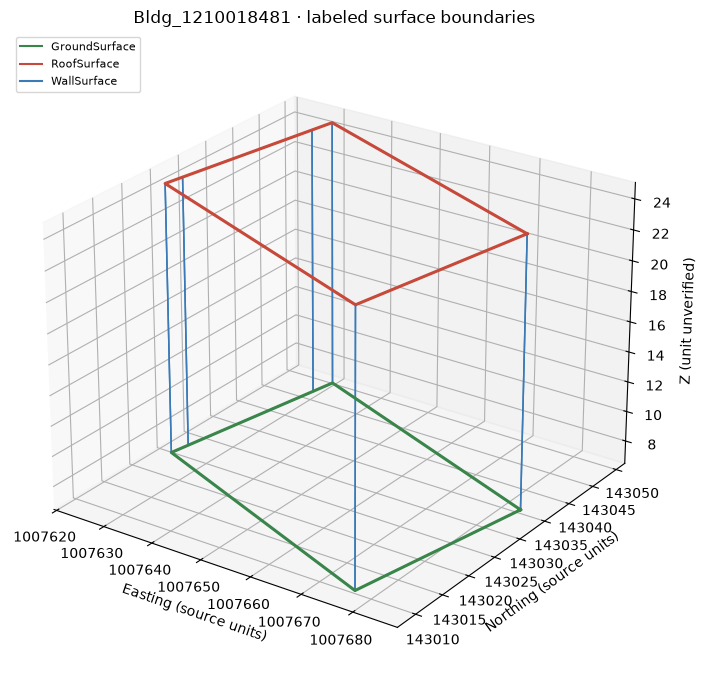

Plotted ring counts: {'RoofSurface': 1, 'GroundSurface': 1, 'WallSurface': 6}


In [6]:
first_id = first_building.get(GML_ID, "(missing gml:id)")
display(building_table.iloc[:1].T.rename(columns={building_table.index[0]: "first building"}))
# Show only the beginning, keeping notebook output manageable.
for prefix, uri in NS.items():
    ET.register_namespace(prefix, uri)
xml_excerpt = ET.tostring(first_building, encoding="unicode")
print(xml_excerpt[:3000] + ("\n… [excerpt truncated]" if len(xml_excerpt) > 3000 else ""))

first_rings = [r for r in rings if r["building"] == first_id]
assert first_rings, "First building has no decoded rings; inspect flags before plotting"
colors = {"RoofSurface": "#c6493a", "WallSurface": "#397ab7", "GroundSurface": "#39854a",
          "ClosureSurface": "#a56bb7", "OuterCeilingSurface": "#d99024", "OuterFloorSurface": "#6d7379"}
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")
# Draw wall edges first so they do not obscure roof and ground outlines.
for ring in sorted(first_rings, key=lambda r: {"WallSurface": 0, "GroundSurface": 1, "RoofSurface": 2}.get(r["surface"], 0)):
    xyz = ring["xyz"]
    ax.plot(xyz[:, 0], xyz[:, 1], xyz[:, 2], color=colors[ring["surface"]],
            linestyle="--" if ring["role"] == "interior" else "-",
            linewidth=1.1 if ring["surface"] == "WallSurface" else 2.2,
            zorder=2 if ring["surface"] == "WallSurface" else 4)
ax.set(xlabel="Easting (source units)", ylabel="Northing (source units)",
       zlabel="Z (unit unverified)", title=f"{building_table.iloc[0]['name']} · labeled surface boundaries")
ax.ticklabel_format(style="plain", useOffset=False)
ax.view_init(elev=25, azim=-55)
ax.legend(handles=[Line2D([0], [0], color=colors[s], label=s) for s in sorted({r["surface"] for r in first_rings})],
          loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()
print("Plotted ring counts:", dict(Counter(r["surface"] for r in first_rings)))

## 6. Findings and next decisions

The following summary is generated from the current sample, so rerunning with a different delivery area does not leave stale findings.

In [7]:
lod_tags = ", ".join(sorted(k for k in element_counts if k.startswith("lod"))) or "none observed"
interiors = sum(r["role"] == "interior" for r in rings)
display(Markdown(f"""
**Observed in {GML_FILE.name}:**
- {len(buildings)} sampled buildings; {len(rings)} valid inline XYZ rings.
- Surface types: {', '.join(sorted(surface_counts))}. LoD tags: {lod_tags}.
- {interiors} decoded interior rings; {len(references)} geometry references; {len(issues)} inspection flags.
- Horizontal CRS: {source_crs.name}. Building metadata: {', '.join(sorted(metadata_counts)) or 'none observed'}.

**Still unknown:** consistency across every file, completeness of detailed roof shapes, Z units and vertical datum, polygon planarity, orientation, and mesh topology. A clean sample is not proof of dataset-wide validity.

**Stage 2 implications:** stream buildings; preserve building/surface IDs, semantic labels, original XYZ and CRS; handle holes and references explicitly; report unsupported geometry. Verify vertical units before physical measurements. Later mesh conversion must retain the link between mesh faces and source surfaces.
"""))


**Observed in DA1_3D_Buildings_Merged.gml:**
- 100 sampled buildings; 1442 valid inline XYZ rings.
- Surface types: GroundSurface, RoofSurface, WallSurface. LoD tags: lod2MultiSurface.
- 0 decoded interior rings; 0 geometry references; 0 inspection flags.
- Horizontal CRS: NAD83 / New York Long Island (ftUS). Building metadata: BIN, DOITT_ID, SOURCE_ID.

**Still unknown:** consistency across every file, completeness of detailed roof shapes, Z units and vertical datum, polygon planarity, orientation, and mesh topology. A clean sample is not proof of dataset-wide validity.

**Stage 2 implications:** stream buildings; preserve building/surface IDs, semantic labels, original XYZ and CRS; handle holes and references explicitly; report unsupported geometry. Verify vertical units before physical measurements. Later mesh conversion must retain the link between mesh faces and source surfaces.


### Context and sources

- [NYC 3D Building Model metadata](https://github.com/CityOfNewYork/nyc-geo-metadata/blob/main/Metadata/Metadata_3DBuildingModel.md): the city describes a model based on the 2014 aerial survey with a hybrid of LoD1 and LoD2 detail. This is context for the dataset, not a guarantee about each sampled roof.
- [OGC CityGML](https://www.ogc.org/standards/citygml/): the standard behind the semantic city model.
- Local evidence: the selected GML's namespaces, envelope, surface tags and coordinates; `DeliveryArea.prj`; and the companion boundary shapefile.

**Next:** review these results together before starting extraction. No mesh conversion, solar suitability calculation, or citywide validation has been performed.